# Titanic Survival Prediction with Naive Bayes

## Imports

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score

## Load Data and Exploratory Data Analysis (EDA)

In [4]:
df = pd.read_csv("titanic.csv")

In [5]:
print("database shape", df.shape)
print("*" * 50)
print("mata info:", df.info())
print("*" * 50)
df.head()

database shape (891, 12)
**************************************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
mata info: None
**************************************************


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Pre-processing



In [7]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

In [8]:
df.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [9]:
df["Age"] = df["Age"].fillna(df.groupby(["Sex", "Pclass"])["Age"].transform("mean"))

In [10]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [11]:
print(df.select_dtypes(exclude="number"))

        Sex Embarked
0      male        S
1    female        C
2    female        S
3    female        S
4      male        S
..      ...      ...
886    male        S
887  female        S
888  female        S
889    male        C
890    male        Q

[891 rows x 2 columns]


In [12]:
df["Sex"] = df["Sex"].replace({"male": 0, "female": 1})

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_4936\2554531933.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Sex"] = df["Sex"].replace({"male": 0, "female": 1})


<div dir="rtl" style="text-align: right;">
برای `Embarked` از One-Hot Encoding استفاده می‌کنیم تا هر بندر ستون جداگانه داشته باشد و ترتیب عددی مصنوعی به دسته‌ها ندهیم.
</div>

In [13]:
df[["Embarked"]]

,Embarked
0,S
1,C
2,S
3,S
4,S
...,...
886,S
887,S
888,S
889,C


In [15]:
df = pd.get_dummies(df, columns=['Embarked'], dtype=int)

In [16]:
df[["Embarked_C", "Embarked_S", "Embarked_Q"]]

,Embarked_C,Embarked_S,Embarked_Q
0,0,1,0
1,1,0,0
2,0,1,0
3,0,1,0
4,0,1,0
...,...,...,...
886,0,1,0
887,0,1,0
888,0,1,0
889,1,0,0


In [18]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [19]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

## Train/Test Split


In [20]:
x = df.drop("Survived", axis=1)
y = df["Survived"]

In [21]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42, stratify = y)
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (712, 10)
Testing data: (179, 10)


## 5. Defining the Naive Bayes Model


In [22]:
model = GaussianNB()


In [23]:
model.fit(x_train, y_train)

,priors,None
,var_smoothing,1e-09


In [25]:
y_pred = model.predict(x_test)

In [26]:
y_pred

array([0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0])

## Display evaluation

<div dir="rtl" style="text-align: right;">
تابع ارزیابی Accuracy، Precision، Recall و F1 را محاسبه می‌کند و Confusion Matrix را برای نمایش پیش‌بینی‌های درست و نادرست رسم می‌کند.
</div>

In [27]:
def evaluation(y_test, y_pred):
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average="macro"))
    print("Recall:", recall_score(y_test, y_pred, average="macro"))
    print("F1 Score:", f1_score(y_test, y_pred, average="macro"))


    

   

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        xticklabels=["Not Survived", "Survived"],
        yticklabels=["Not Survived", "Survived"])

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Decision Tree Confusion Matrix")

    plt.show()

Accuracy: 0.770949720670391
Precision: 0.7583465818759937
Recall: 0.7569169960474309
F1 Score: 0.7576047825081745


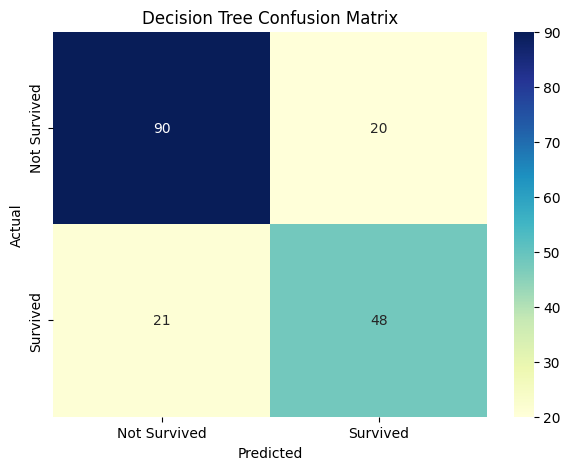

In [28]:
evaluation(y_test, y_pred)

In [32]:
y_prob = model.predict_proba(x_test)
y_prob[:5]

array([[0.99399386, 0.00600614],
       [0.96417412, 0.03582588],
       [0.58014838, 0.41985162],
       [0.99502948, 0.00497052],
       [0.05315435, 0.94684565]])

## Predicting New Passengers



In [33]:
new_passengers = pd.DataFrame([
    {   # male, 3rd class, travelling alone
        "Pclass": 3, "Sex": 0, "Age": 25, "SibSp": 0, "Parch": 0,
        "Fare": 7.25, "Embarked_C": 1, "Embarked_Q": 0, "Embarked_S": 0, "FamilySize": 1
    },
    {   # female, 1st class, with her spouse
        "Pclass": 1, "Sex": 1, "Age": 38, "SibSp": 1, "Parch": 0,
        "Fare": 71.28, "Embarked_C": 0,"Embarked_Q": 0,"Embarked_S": 1, "FamilySize": 2
    },
    {   # boy, 2nd class, with a sibling and two parents
        "Pclass": 2, "Sex": 0, "Age": 8, "SibSp": 1, "Parch": 2,
        "Fare": 30.0, "Embarked_C": 0, "Embarked_Q": 1, "Embarked_S": 0, "FamilySize": 4
    },
])

display(new_passengers)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,FamilySize
0,3,0,25,0,0,7.25,1,0,0,1
1,1,1,38,1,0,71.28,0,0,1,2
2,2,0,8,1,2,30.00,0,1,0,4


In [34]:
predictions = model.predict(new_passengers)

for i in range(len(predictions)):
    if predictions[i] == 1:
        print(f"Passenger {i + 1}: Survived")
    else:
        print(f"Passenger {i + 1}: Did not survive")


Passenger 1: Did not survive
Passenger 2: Survived
Passenger 3: Did not survive


In [35]:
prob= model.predict_proba(new_passengers)
prob

array([[0.59295064, 0.40704936],
       [0.02460509, 0.97539491],
       [0.53440312, 0.46559688]])